## Recurrent PPO with GTrXL: Droplet Protocol Tracing

This notebook implements Recurrent PPO with Gated Transformer-XL (GTrXL) for 
reverse-engineering droplet protocols on DMFBs.

### Features:
- **GTrXL Memory**: Full Transformer-XL architecture for long-term dependencies
- **Action Masking**: Belief-state based masking via logit manipulation
- **Vectorized Environments**: Parallel training for faster convergence
- **Custom Feature Extractor**: CNN for voltage history + MLP for scalar observations

### Architecture:
CustomFeatureExtractor → GTrXL Transformer → Actor (policy) + Critic (value)

### References:
- MarcoMeter/episodic-transformer-memory-ppo

```bibtex
@misc{parisotto2019stabilizingtransformersreinforcementlearning,
  title={Stabilizing Transformers for Reinforcement Learning}, 
  author={Emilio Parisotto and H. Francis Song and Jack W. Rae and Razvan Pascanu and Caglar Gulcehre and Siddhant M. Jayakumar and Max Jaderberg and Raphael Lopez Kaufman and Aidan Clark and Seb Noury and Matthew M. Botvinick and Nicolas Heess and Raia Hadsell},
  year={2019},
  eprint={1910.06764},
  archivePrefix={arXiv},
  primaryClass={cs.LG},
  url={https://arxiv.org/abs/1910.06764}, 
}

@misc{schulman2017proximalpolicyoptimizationalgorithms,
      title={Proximal Policy Optimization Algorithms}, 
      author={John Schulman and Filip Wolski and Prafulla Dhariwal and Alec Radford and Oleg Klimov},
      year={2017},
      eprint={1707.06347},
      archivePrefix={arXiv},
      primaryClass={cs.LG},
      url={https://arxiv.org/abs/1707.06347}, 
}


## Import Libraries

In [2]:
# importing necessary libraries
import time
import os 
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from collections import deque
from torch.utils.tensorboard import SummaryWriter
from torch.distributions import Categorical
from tqdm import tqdm
import pickle
import matplotlib.pyplot as plt
import json
import gymnasium as gym
from einops import rearrange

## GTrXL Components

The Gated Transformer-XL architecture with positional encoding, multi-head attention, and transformer layers.

In [3]:
def layer_init(layer, std=np.sqrt(2), bias_const=0.0):
    """Initialize layer with orthogonal weights."""
    torch.nn.init.orthogonal_(layer.weight, std)
    if layer.bias is not None:
        torch.nn.init.constant_(layer.bias, bias_const)
    return layer


def batched_index_select(input, dim, index):
    """Select indices from batched tensor along a dimension."""
    for ii in range(1, len(input.shape)):
        if ii != dim:
            index = index.unsqueeze(ii)
    expanse = list(input.shape)
    expanse[0] = -1
    expanse[dim] = -1
    index = index.expand(expanse)
    return torch.gather(input, dim, index)


class PositionalEncoding(nn.Module):
    """Sinusoidal positional encoding for transformer."""
    
    def __init__(self, dim, min_timescale=2.0, max_timescale=1e4):
        super().__init__()
        freqs = torch.arange(0, dim, min_timescale)
        inv_freqs = max_timescale ** (-freqs / dim)
        self.register_buffer("inv_freqs", inv_freqs)

    def forward(self, seq_len):
        seq = torch.arange(seq_len - 1, -1, -1.0)
        sinusoidal_inp = rearrange(seq, "n -> n ()") * rearrange(self.inv_freqs, "d -> () d")
        pos_emb = torch.cat((sinusoidal_inp.sin(), sinusoidal_inp.cos()), dim=-1)
        return pos_emb


class MultiHeadAttention(nn.Module):
    """Multi Head Attention without dropout."""

    def __init__(self, embed_dim, num_heads):
        super().__init__()
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_size = embed_dim // num_heads

        assert self.head_size * num_heads == embed_dim, "Embedding dim must be divisible by num_heads"

        self.values = nn.Linear(self.head_size, self.head_size, bias=False)
        self.keys = nn.Linear(self.head_size, self.head_size, bias=False)
        self.queries = nn.Linear(self.head_size, self.head_size, bias=False)
        self.fc_out = nn.Linear(self.num_heads * self.head_size, embed_dim)

    def forward(self, values, keys, query, mask):
        N = query.shape[0]
        value_len, key_len, query_len = values.shape[1], keys.shape[1], query.shape[1]

        values = values.reshape(N, value_len, self.num_heads, self.head_size)
        keys = keys.reshape(N, key_len, self.num_heads, self.head_size)
        query = query.reshape(N, query_len, self.num_heads, self.head_size)

        values = self.values(values)
        keys = self.keys(keys)
        queries = self.queries(query)

        energy = torch.einsum("nqhd,nkhd->nhqk", [queries, keys])

        if mask is not None:
            energy = energy.masked_fill(mask.unsqueeze(1).unsqueeze(1) == 0, float("-1e20"))

        attention = torch.softmax(energy / (self.embed_dim ** (1 / 2)), dim=3)
        out = torch.einsum("nhql,nlhd->nqhd", [attention, values]).reshape(
            N, query_len, self.num_heads * self.head_size
        )

        return self.fc_out(out), attention


class TransformerLayer(nn.Module):
    """Single transformer layer with pre-layer normalization."""
    
    def __init__(self, dim, num_heads):
        super().__init__()
        self.attention = MultiHeadAttention(dim, num_heads)
        self.layer_norm_q = nn.LayerNorm(dim)
        self.norm_kv = nn.LayerNorm(dim)
        self.layer_norm_attn = nn.LayerNorm(dim)
        self.fc_projection = nn.Sequential(nn.Linear(dim, dim), nn.ReLU())

    def forward(self, value, key, query, mask):
        query_ = self.layer_norm_q(query)
        value = self.norm_kv(value)
        key = value
        attention, attention_weights = self.attention(value, key, query_, mask)
        x = attention + query
        x_ = self.layer_norm_attn(x)
        forward = self.fc_projection(x_)
        out = forward + x
        return out, attention_weights


class Transformer(nn.Module):
    """Transformer-XL with sliding memory window."""
    
    def __init__(self, num_layers, dim, num_heads, max_episode_steps, positional_encoding):
        super().__init__()
        self.max_episode_steps = max_episode_steps
        self.positional_encoding = positional_encoding
        
        if positional_encoding == "absolute":
            self.pos_embedding = PositionalEncoding(dim)
        elif positional_encoding == "learned":
            self.pos_embedding = nn.Parameter(torch.randn(max_episode_steps, dim))
            
        self.transformer_layers = nn.ModuleList([
            TransformerLayer(dim, num_heads) for _ in range(num_layers)
        ])

    def forward(self, x, memories, mask, memory_indices):
        if self.positional_encoding == "absolute":
            pos_embedding = self.pos_embedding(self.max_episode_steps)[memory_indices]
            memories = memories + pos_embedding.unsqueeze(2)
        elif self.positional_encoding == "learned":
            memories = memories + self.pos_embedding[memory_indices].unsqueeze(2)

        out_memories = []
        for i, layer in enumerate(self.transformer_layers):
            out_memories.append(x.detach())
            x, attention_weights = layer(memories[:, :, i], memories[:, :, i], x.unsqueeze(1), mask)
            x = x.squeeze()
            if len(x.shape) == 1:
                x = x.unsqueeze(0)
        return x, torch.stack(out_memories, dim=1)

## PPO Agent with GTrXL and Action Masking

The PPO agent uses CustomFeatureExtractor for observation encoding, followed by a GTrXL transformer for memory, and separate actor/critic heads with action masking support.

In [ ]:
# Import custom environment and feature extractor
from Env import VoltageDistributionEnv
from CustomFeatureExtractor import CustomFeatureExtractor

class RecurrentPPOAgent:
    """
    Recurrent PPO Agent with GTrXL Memory

    - CustomFeatureExtractor for dict observation space
    - GTrXL transformer for long-term memory
    - Action masking via logit manipulation
    - Vectorized environment support
    - metrics stored to tensorboard for debugging 
    """
    
    def __init__(self,
                 env_constructor,
                 feature_extractor_constructor,
                 action_dim,

                 # GTrXL hyperparameters
                 trxl_dim=256,
                 trxl_num_layers=2,
                 trxl_num_heads=4,
                 trxl_memory_length=32,
                 trxl_positional_encoding="absolute",

                 # PPO hyperparameters
                 gamma=0.99,
                 gae_lambda=0.95,
                 lr=3e-4,
                 clip_coef=0.2,
                 vf_coef=0.5,
                 ent_coef=0.01,
                 max_grad_norm=0.5,
                 update_epochs=4,
                 num_minibatches=4,
                 norm_adv=True,
                 clip_vloss=True,

                 # Training settings
                 num_envs=4,
                 num_steps=128,
                 training_steps=10_000,

                 # Logging
                 tensorboard_dir=None,
                 run_name=None,

                 # Action masking
                 action_mask=False):
        
        self.env_constructor = env_constructor
        self.feature_extractor_constructor = feature_extractor_constructor
        self.action_dim = action_dim
        
        # GTrXL params
        self.trxl_dim = trxl_dim
        self.trxl_num_layers = trxl_num_layers
        self.trxl_num_heads = trxl_num_heads
        self.trxl_memory_length = trxl_memory_length
        self.trxl_positional_encoding = trxl_positional_encoding
        
        # PPO params
        self.gamma = gamma
        self.gae_lambda = gae_lambda
        self.lr = lr
        self.clip_coef = clip_coef
        self.vf_coef = vf_coef
        self.ent_coef = ent_coef
        self.max_grad_norm = max_grad_norm
        self.update_epochs = update_epochs
        self.num_minibatches = num_minibatches
        self.norm_adv = norm_adv
        self.clip_vloss = clip_vloss
        
        # Training params
        self.num_envs = num_envs
        self.num_steps = num_steps
        self.training_steps = training_steps
        self.action_mask_enabled = action_mask
        
        # Device
        self.device = torch.device('cpu')
        
        # single env instance to get observation space
        single_env = env_constructor()
        self.observation_space = single_env.observation_space
        
        # Get max episode steps
        self.max_episode_steps = getattr(single_env, 'length', 50)
        if hasattr(single_env, 'spec') and single_env.spec and single_env.spec.max_episode_steps:
            self.max_episode_steps = single_env.spec.max_episode_steps
        self.max_episode_steps = max(self.max_episode_steps, 100)  # Ensure reasonable default
        single_env.close()
        
        # Ensure memory length doesn't exceed max episode steps
        self.trxl_memory_length = min(self.trxl_memory_length, self.max_episode_steps)
        
        # Build networks
        self.agent = self._build_agent()
        self.optimizer = optim.Adam(self.agent.parameters(), lr=lr)
        
        # TensorBoard
        if tensorboard_dir and run_name:
            log_dir = os.path.join(tensorboard_dir, run_name)
            self.writer = SummaryWriter(log_dir=log_dir)
            print(f"TensorBoard logging to: {log_dir}")
        elif tensorboard_dir:
            self.writer = SummaryWriter(log_dir=tensorboard_dir)
        else:
            self.writer = None
        
        # Counters
        self.global_step = 0
        self.episode_count = 0
        self.update_count = 0
        
        # Computed values
        self.batch_size = num_envs * num_steps
        self.minibatch_size = self.batch_size // num_minibatches
        
        print(f"\nRecurrentPPO Agent initialized")
        print(f" Action dim: {action_dim}")
        print(f" Action masking: {action_mask}\n")
    
    def _build_agent(self):
        """Build the PPO agent network."""
        
        class PPOGTrXLAgent(nn.Module):
            """PPO Agent with CustomFeatureExtractor and GTrXL."""
            
            def __init__(self, parent):
                super().__init__()
                self.parent = parent
                
                # Feature extractor (CustomFeatureExtractor)
                self.feature_extractor = parent.feature_extractor_constructor(parent.observation_space)
                feat_dim = self.feature_extractor._features_dim
                
                # Project features to transformer dimension
                self.feature_projection = nn.Sequential(
                    layer_init(nn.Linear(feat_dim, parent.trxl_dim)),
                    nn.ReLU(),
                )
                
                # GTrXL Transformer
                self.transformer = Transformer(
                    parent.trxl_num_layers,
                    parent.trxl_dim,
                    parent.trxl_num_heads,
                    parent.max_episode_steps,
                    parent.trxl_positional_encoding
                )
                
                # Post-transformer processing
                self.hidden_post_trxl = nn.Sequential(
                    layer_init(nn.Linear(parent.trxl_dim, parent.trxl_dim)),
                    nn.ReLU(),
                )
                
                # Actor head (policy) - separate hidden layer for policy
                self.actor_hidden = nn.Sequential(
                    layer_init(nn.Linear(parent.trxl_dim, parent.trxl_dim)),
                    nn.ReLU(),
                )
                self.actor = layer_init(nn.Linear(parent.trxl_dim, parent.action_dim), std=0.01)
                
                # Critic head (value) - separate hidden layer for value
                self.critic_hidden = nn.Sequential(
                    layer_init(nn.Linear(parent.trxl_dim, parent.trxl_dim)),
                    nn.ReLU(),
                )
                self.critic = layer_init(nn.Linear(parent.trxl_dim, 1), std=1.0)
            
            def _process_dict_obs(self, obs_dict, batch_size, seq_len=1):
                """Process dictionary observations through feature extractor."""
                # Flatten batch and sequence for feature extraction
                if seq_len > 1:
                    flat_obs = {k: v.reshape(batch_size * seq_len, *v.shape[2:]) for k, v in obs_dict.items()}
                else:
                    flat_obs = obs_dict
                
                features = self.feature_extractor(flat_obs)
                if seq_len > 1:
                    features = features.view(batch_size, seq_len, -1)
                
                return features
            
            def get_value(self, obs_dict, memory, memory_mask, memory_indices):
                """Get value estimate for observations."""
                B = obs_dict[list(obs_dict.keys())[0]].shape[0]
                
                features = self._process_dict_obs(obs_dict, B)
                x = self.feature_projection(features)
                x, _ = self.transformer(x, memory, memory_mask, memory_indices)
                x = self.hidden_post_trxl(x)
                
                # Value head
                h_value = self.critic_hidden(x)
                return self.critic(h_value).flatten()
            
            def get_action_and_value(self, obs_dict, memory, memory_mask, memory_indices, 
                                     action=None, action_mask=None):
                """Get action, log_prob, entropy, value, and new_memory."""
                B = obs_dict[list(obs_dict.keys())[0]].shape[0]
                
                features = self._process_dict_obs(obs_dict, B)
                x = self.feature_projection(features)
                x, new_memory = self.transformer(x, memory, memory_mask, memory_indices)
                x = self.hidden_post_trxl(x)
                
                # Policy head
                h_policy = self.actor_hidden(x)
                logits = self.actor(h_policy)
                
                # Apply action mask (set invalid action logits to -inf)
                if action_mask is not None:
                    logits = logits.masked_fill(action_mask == 0, float('-1e8'))
                
                # Create distribution
                dist = Categorical(logits=logits)
                
                if action is None:
                    action = dist.sample()
                
                log_prob = dist.log_prob(action)
                entropy = dist.entropy()
                
                # Value head
                h_value = self.critic_hidden(x)
                value = self.critic(h_value).flatten()
                
                return action, log_prob, entropy, value, new_memory
        
        return PPOGTrXLAgent(self).to(self.device)
    
    def _make_vec_env(self):
        """Create vectorized environments."""
        def make_env(idx):
            def thunk():
                env = self.env_constructor()
                env = gym.wrappers.RecordEpisodeStatistics(env)
                return env
            return thunk
    
        return gym.vector.SyncVectorEnv([make_env(i) for i in range(self.num_envs)])
    
    def _obs_dict_to_tensor(self, obs_dict, device):
        """Convert numpy observation dict to tensor dict."""
        return {k: torch.from_numpy(v).float().to(device) for k, v in obs_dict.items()}
    
    def train(self):
        """Main training loop."""
        
        # Create vectorized environment
        envs = self._make_vec_env()
        
        # Storage buffers
        obs_buffer = {k: torch.zeros((self.num_steps, self.num_envs, *v.shape)).to(self.device)
                      for k, v in self.observation_space.spaces.items()}
        actions = torch.zeros((self.num_steps, self.num_envs), dtype=torch.long).to(self.device)
        log_probs = torch.zeros((self.num_steps, self.num_envs)).to(self.device)
        rewards = torch.zeros((self.num_steps, self.num_envs)).to(self.device)
        dones = torch.zeros((self.num_steps, self.num_envs)).to(self.device)
        values = torch.zeros((self.num_steps, self.num_envs)).to(self.device)
        action_masks_buffer = torch.ones((self.num_steps, self.num_envs, self.action_dim)).to(self.device)
        
        # Memory buffers
        stored_memories = []
        stored_memory_masks = torch.zeros((self.num_steps, self.num_envs, self.trxl_memory_length), dtype=torch.bool).to(self.device)
        stored_memory_index = torch.zeros((self.num_steps, self.num_envs), dtype=torch.long).to(self.device)
        stored_memory_indices = torch.zeros((self.num_steps, self.num_envs, self.trxl_memory_length), dtype=torch.long).to(self.device)
        
        # Memory mask and indices setup
        memory_mask = torch.tril(torch.ones((self.trxl_memory_length, self.trxl_memory_length)), diagonal=-1).to(self.device)
        repetitions = torch.repeat_interleave(
            torch.arange(0, self.trxl_memory_length).unsqueeze(0), self.trxl_memory_length - 1, dim=0
        ).long().to(self.device)
        memory_indices = torch.stack([
            torch.arange(i, i + self.trxl_memory_length) 
            for i in range(self.max_episode_steps - self.trxl_memory_length + 1)
        ]).long().to(self.device)
        memory_indices = torch.cat((repetitions, memory_indices))
        
        # Initialize environment and memory
        next_obs_np, infos = envs.reset()
        next_obs = self._obs_dict_to_tensor(next_obs_np, self.device)
        next_done = torch.zeros(self.num_envs).to(self.device)
        next_memory = torch.zeros((self.num_envs, self.max_episode_steps, self.trxl_num_layers, self.trxl_dim), 
                                   dtype=torch.float32).to(self.device)
        env_current_episode_step = torch.zeros((self.num_envs,), dtype=torch.long).to(self.device)
        
        # Get initial action masks
        next_action_mask = None
        if self.action_mask_enabled:
            next_action_mask = torch.ones((self.num_envs, self.action_dim)).to(self.device)
            for i, info in enumerate(infos.get('action_mask', [None] * self.num_envs) if isinstance(infos, dict) else [None] * self.num_envs):
                if info is not None:
                    next_action_mask[i] = torch.from_numpy(np.array(info)).float().to(self.device)
            # Handle vectorized info format
            if 'action_mask' in infos:
                for i in range(self.num_envs):
                    if infos['action_mask'][i] is not None:
                        next_action_mask[i] = torch.from_numpy(np.array(infos['action_mask'][i])).float().to(self.device)
        
        # Episode tracking
        episode_return_window = deque(maxlen=100)
        episode_normalized_return_window = deque(maxlen=100)
        episode_length_window = deque(maxlen=100)
        start_time = time.time()
        
        # Training loop
        num_iterations = self.training_steps // self.batch_size + 1
        
        with tqdm(total=self.training_steps, desc="Training RecurrentPPO", unit="step") as pbar:
            print("\n ________________________ Training RecurrentPPO Agent ________________________\n")
            
            for iteration in range(1, num_iterations + 1):
                if self.global_step >= self.training_steps:
                    break
                
                # Initialize memory storage for this rollout
                stored_memories = [next_memory[e].clone() for e in range(self.num_envs)]
                for e in range(self.num_envs):
                    stored_memory_index[:, e] = e
                
                # Collect rollout
                for step in range(self.num_steps):
                    if self.global_step >= self.training_steps:
                        break
                    
                    self.global_step += self.num_envs
                    
                    with torch.no_grad():
                        # Store observations
                        for k in next_obs.keys():
                            obs_buffer[k][step] = next_obs[k]
                        dones[step] = next_done
                        
                        # Store memory info
                        stored_memory_masks[step] = memory_mask[torch.clip(env_current_episode_step, 0, self.trxl_memory_length - 1)]
                        stored_memory_indices[step] = memory_indices[env_current_episode_step]
                        
                        # Get memory window
                        memory_window = batched_index_select(next_memory, 1, stored_memory_indices[step])
                        
                        # Store action mask
                        if self.action_mask_enabled and next_action_mask is not None:
                            action_masks_buffer[step] = next_action_mask
                        
                        # Get action and value
                        action, log_prob, _, value, new_memory = self.agent.get_action_and_value(
                            next_obs, memory_window, stored_memory_masks[step], stored_memory_indices[step],
                            action_mask=next_action_mask if self.action_mask_enabled else None
                        )
                        
                        # Update memory
                        for e in range(self.num_envs):
                            next_memory[e, env_current_episode_step[e]] = new_memory[e]
                        
                        # Store action, log_prob, value
                        actions[step] = action
                        log_probs[step] = log_prob
                        values[step] = value
                    
                    # Step environment
                    next_obs_np, reward, terminated, truncated, infos = envs.step(action.cpu().numpy())
                    next_done_np = np.logical_or(terminated, truncated)
                    
                    rewards[step] = torch.tensor(reward).to(self.device)
                    next_obs = self._obs_dict_to_tensor(next_obs_np, self.device)
                    next_done = torch.tensor(next_done_np).float().to(self.device)
                    
                    # Update action masks from info
                    if self.action_mask_enabled:
                        next_action_mask = torch.ones((self.num_envs, self.action_dim)).to(self.device)
                        # Handle different info formats from vectorized envs
                        if 'final_info' in infos:
                            for i, final_info in enumerate(infos['final_info']):
                                if final_info is not None and 'action_mask' in final_info:
                                    next_action_mask[i] = torch.from_numpy(np.array(final_info['action_mask'])).float().to(self.device)
                                elif not next_done_np[i]:
                                    # For non-terminal states, try to get mask from regular info
                                    pass
                        # Try direct access pattern
                        if 'action_mask' in infos:
                            for i in range(self.num_envs):
                                mask = infos['action_mask'][i] if isinstance(infos['action_mask'], (list, np.ndarray)) else infos['action_mask']
                                if mask is not None:
                                    next_action_mask[i] = torch.from_numpy(np.array(mask)).float().to(self.device)
                    
                    # Handle episode ends
                    for idx, done in enumerate(next_done_np):
                        if done:
                            env_current_episode_step[idx] = 0
                            mem_index = stored_memory_index[step, idx]
                            stored_memories[mem_index] = stored_memories[mem_index].clone()
                            next_memory[idx] = torch.zeros(
                                (self.max_episode_steps, self.trxl_num_layers, self.trxl_dim), 
                                dtype=torch.float32
                            ).to(self.device)
                            if step < self.num_steps - 1:
                                stored_memories.append(next_memory[idx])
                                stored_memory_index[step + 1:, idx] = len(stored_memories) - 1
                        else:
                            env_current_episode_step[idx] += 1
                    
                    # Log episode completions - handle gymnasium vectorized env info format
                    if 'episode' in infos and isinstance(infos['episode'], dict):
                        ep_data = infos['episode']
                        for i in range(self.num_envs):
                            if next_done_np[i]:  # Only valid when episode ended
                                ep_return = float(ep_data['r'][i])
                                ep_length = int(ep_data['l'][i])
                                self.episode_count += 1
                                episode_return_window.append(ep_return)
                                normalized_return = ep_return / ep_length if ep_length > 0 else 0
                                episode_normalized_return_window.append(normalized_return)
                                episode_length_window.append(ep_length)
                                
                                # Log to TensorBoard (matching RecurrentDQN format exactly)
                                if self.writer:
                                    # Per-step metrics (rolling averages)
                                    self.writer.add_scalar('rollout/ep_rew_mean', np.mean(episode_return_window), self.global_step)
                                    self.writer.add_scalar('rollout/ep_len_mean', ep_length, self.global_step)
                                    self.writer.add_scalar('rollout/normalized_return_mean', np.mean(episode_normalized_return_window), self.global_step)
                                    # Per-episode metrics
                                    self.writer.add_scalar('train/episode_reward', ep_return, self.episode_count)
                                    self.writer.add_scalar('rollout/normalized_return', normalized_return, self.episode_count)
                                    self.writer.flush()
                    
                    pbar.update(self.num_envs)
                
                # Bootstrap value
                with torch.no_grad():
                    indices = memory_indices[env_current_episode_step]
                    memory_window = batched_index_select(next_memory, 1, indices)
                    next_value = self.agent.get_value(
                        next_obs, memory_window,
                        memory_mask[torch.clip(env_current_episode_step, 0, self.trxl_memory_length - 1)],
                        indices
                    )
                    
                    # GAE: Generalized Advantage Estimation
                    advantages = torch.zeros_like(rewards).to(self.device)
                    lastgaelam = 0
                    for t in reversed(range(self.num_steps)):
                        if t == self.num_steps - 1:
                            nextnonterminal = 1.0 - next_done
                            nextvalues = next_value
                        else:
                            nextnonterminal = 1.0 - dones[t + 1]
                            nextvalues = values[t + 1]
                        delta = rewards[t] + self.gamma * nextvalues * nextnonterminal - values[t]
                        advantages[t] = lastgaelam = delta + self.gamma * self.gae_lambda * nextnonterminal * lastgaelam
                    returns = advantages + values
                
                # Flatten batches
                b_obs = {k: v.reshape(-1, *v.shape[2:]) for k, v in obs_buffer.items()}
                b_log_probs = log_probs.reshape(-1)
                b_actions = actions.reshape(-1)
                b_advantages = advantages.reshape(-1)
                b_returns = returns.reshape(-1)
                b_values = values.reshape(-1)
                b_action_masks = action_masks_buffer.reshape(-1, self.action_dim)
                b_memory_index = stored_memory_index.reshape(-1)
                b_memory_indices = stored_memory_indices.reshape(-1, self.trxl_memory_length)
                b_memory_mask = stored_memory_masks.reshape(-1, self.trxl_memory_length)
                stored_memories_tensor = torch.stack(stored_memories, dim=0)
                
                # PPO update
                clipfracs = []
                for epoch in range(self.update_epochs):
                    b_inds = torch.randperm(self.batch_size)
                    for start in range(0, self.batch_size, self.minibatch_size):
                        end = start + self.minibatch_size
                        mb_inds = b_inds[start:end]
                        
                        mb_obs = {k: v[mb_inds] for k, v in b_obs.items()}
                        mb_memories = stored_memories_tensor[b_memory_index[mb_inds]]
                        mb_memory_windows = batched_index_select(mb_memories, 1, b_memory_indices[mb_inds])
                        
                        _, newlogprob, entropy, newvalue, _ = self.agent.get_action_and_value(
                            mb_obs, mb_memory_windows, b_memory_mask[mb_inds], b_memory_indices[mb_inds],
                            action=b_actions[mb_inds],
                            action_mask=b_action_masks[mb_inds] if self.action_mask_enabled else None
                        )
                        
                        # Policy loss
                        mb_advantages = b_advantages[mb_inds]
                        if self.norm_adv:
                            mb_advantages = (mb_advantages - mb_advantages.mean()) / (mb_advantages.std() + 1e-8)
                        
                        logratio = newlogprob - b_log_probs[mb_inds]
                        ratio = torch.exp(logratio)
                        
                        pg_loss1 = -mb_advantages * ratio
                        pg_loss2 = -mb_advantages * torch.clamp(ratio, 1.0 - self.clip_coef, 1.0 + self.clip_coef)
                        pg_loss = torch.max(pg_loss1, pg_loss2).mean()
                        

                        # normalizing returns and values across minibatch for value loss stability
                        returns_min = b_returns.min()
                        returns_max = b_returns.max()

                        den = returns_max - returns_min + 1e-8

                        normalized_returns = (b_returns - returns_min) / den
                        normalized_values = (newvalue - returns_min) / den

                        # Value loss
                        if self.clip_vloss:
                            v_loss_unclipped = (normalized_values - normalized_returns[mb_inds]) ** 2
                            v_clipped = ((b_values[mb_inds] - returns_min) / den) + torch.clamp(
                                normalized_values - ((b_values[mb_inds] - returns_min) / den),
                                -self.clip_coef,
                                self.clip_coef
                            )
                            v_loss_clipped = (v_clipped - normalized_returns[mb_inds]) ** 2
                            v_loss = torch.max(v_loss_unclipped, v_loss_clipped).mean()
                        else:
                            v_loss = ((normalized_values - normalized_returns[mb_inds]) ** 2).mean()
                        
                        # Entropy loss
                        entropy_loss = entropy.mean() / np.log(self.action_dim)

                        # Total loss (standard PPO loss) policy loss + value loss + entropy loss 
                        loss = pg_loss - (self.ent_coef * entropy_loss) + (self.vf_coef * v_loss)
                        
                        self.optimizer.zero_grad()
                        loss.backward()
                        nn.utils.clip_grad_norm_(self.agent.parameters(), self.max_grad_norm)
                        self.optimizer.step()
                        
                        self.update_count += 1
                        
                        # Track clip fraction
                        with torch.no_grad():
                            clipfracs.append(((ratio - 1.0).abs() > self.clip_coef).float().mean().item())
                            approx_kl = ((ratio - 1) - logratio).mean().item()
                
                # Logging - log losses per iteration
                if self.writer:
                    self.writer.add_scalar('losses/policy_loss', pg_loss.item(), self.global_step)
                    self.writer.add_scalar('losses/value_loss', v_loss.item(), self.global_step)
                    self.writer.add_scalar('losses/entropy', entropy_loss.item(), self.global_step)
                    self.writer.add_scalar('losses/total_loss', loss.item(), self.global_step)
                    self.writer.add_scalar('losses/clipfrac', np.mean(clipfracs), self.global_step)
                    self.writer.add_scalar('losses/approx_kl', approx_kl, self.global_step)
                    self.writer.flush()
                
                # Print episode count for debugging
                if iteration % 5 == 0:
                    print(f"Iter {iteration}: Episodes completed = {self.episode_count}, ep_rew_mean = {np.mean(episode_return_window) if len(episode_return_window) > 0 else 'N/A'}")
        
        # Cleanup
        envs.close()
        if self.writer:
            log_dir = self.writer.log_dir
            self.writer.close()
            print(f"\nTensorBoard logs saved to: {log_dir}")
            print(f"To view: tensorboard --logdir={log_dir}")
        
        print("\n________________ Training Complete _________________\n")
    
    def save_complete(self, filepath):
        """Save complete agent (PKL format)."""
        save_dict = {
            'agent_state_dict': self.agent.state_dict(),
            'optimizer_state_dict': self.optimizer.state_dict(),
            'global_step': self.global_step,
            'episode_count': self.episode_count,
            'update_count': self.update_count,
            'init_params': {
                'action_dim': self.action_dim,
                'trxl_dim': self.trxl_dim,
                'trxl_num_layers': self.trxl_num_layers,
                'trxl_num_heads': self.trxl_num_heads,
                'trxl_memory_length': self.trxl_memory_length,
                'trxl_positional_encoding': self.trxl_positional_encoding,
                'gamma': self.gamma,
                'gae_lambda': self.gae_lambda,
                'lr': self.lr,
                'clip_coef': self.clip_coef,
                'vf_coef': self.vf_coef,
                'ent_coef': self.ent_coef,
                'max_grad_norm': self.max_grad_norm,
                'update_epochs': self.update_epochs,
                'num_minibatches': self.num_minibatches,
                'norm_adv': self.norm_adv,
                'clip_vloss': self.clip_vloss,
                'num_envs': self.num_envs,
                'num_steps': self.num_steps,
                'training_steps': self.training_steps,
                'action_mask': self.action_mask_enabled,
            }
        }
        
        if not filepath.endswith('.pkl'):
            filepath = filepath.replace('.pth', '.pkl')
        
        os.makedirs(os.path.dirname(filepath), exist_ok=True)
        
        with open(filepath, 'wb') as f:
            pickle.dump(save_dict, f)
        
        print(f"Complete RecurrentPPO agent saved to: {filepath}")
    
    @classmethod
    def load_complete(cls, filepath, env_constructor, feature_extractor_constructor):
        """Load complete agent from PKL file."""
        with open(filepath, 'rb') as f:
            save_dict = pickle.load(f)
        
        init_params = save_dict['init_params']
        agent = cls(
            env_constructor=env_constructor,
            feature_extractor_constructor=feature_extractor_constructor,
            **init_params
        )
        
        agent.agent.load_state_dict(save_dict['agent_state_dict'])
        agent.optimizer.load_state_dict(save_dict['optimizer_state_dict'])
        agent.global_step = save_dict['global_step']
        agent.episode_count = save_dict['episode_count']
        agent.update_count = save_dict['update_count']
        
        print(f"RecurrentPPO agent loaded from: {filepath}")
        print(f"Trained for {agent.global_step} steps, {agent.episode_count} episodes")
        
        return agent

/Users/biplovebaral/Desktop/research/Droplet_Tracker_Modularized/official_repo/RRDQNvenv/lib/python3.12/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


## Train Agent

Configure hyperparameters and start training. The agent logs the same metrics as RecurrentDQN.

**TensorBoard Logging (matches RecurrentDQN exactly):**
- `rollout/ep_rew_mean`: Average episode reward (last 100 episodes, indexed by global_step)
- `rollout/ep_len_mean`: Episode length (indexed by global_step)
- `rollout/normalized_return`: Per-episode normalized return (indexed by episode_count)
- `rollout/normalized_return_mean`: Average normalized return (last 100 episodes, indexed by global_step)
- `train/episode_reward`: Per-episode reward (indexed by episode_count)
- `train/aux_loss`: Auxiliary belief prediction loss (indexed by global_step)

**Run TensorBoard:** `tensorboard --logdir models/tensorboard`

In [5]:
# Get action space dimension
env_instance = VoltageDistributionEnv()
action_dim = env_instance.action_space.n
print(f"Action dimension: {action_dim}")

Action dimension: 70


In [10]:
PPOagent = RecurrentPPOAgent(
    env_constructor=lambda: VoltageDistributionEnv(),
    feature_extractor_constructor=lambda obs_space: CustomFeatureExtractor(obs_space),
    action_dim=action_dim,
    
    # GTrXL Hyperparameters
    trxl_dim=256,                    # Transformer hidden dimension
    trxl_num_layers=2,               # Number of transformer layers
    trxl_num_heads=4,                # Attention heads
    trxl_memory_length=32,           # Memory window length
    trxl_positional_encoding="absolute",  # Positional encoding type
    
    # PPO Hyperparameters
    gamma=0.99,                      # Discount factor
    gae_lambda=0.95,                 # GAE lambda
    lr=3e-4,                         # Learning rate
    clip_coef=0.15,                  # PPO clip coefficient
    vf_coef=0.5,                     # Value function loss coefficient
    ent_coef=0.01,                   # Entropy bonus coefficient
    max_grad_norm=0.5,               # Gradient clipping
    update_epochs=6,                 # PPO epochs per rollout
    num_minibatches=4,               # Minibatches per update
    norm_adv=True,                   # Normalize advantages
    clip_vloss=True,                 # Clip value loss
    
    # Training Settings
    num_envs=8,                      # Number of parallel environments
    num_steps=128,                   # Steps per rollout per env
    training_steps=100_000,          # Total training steps (test run)
    
    # TensorBoard Logging
    tensorboard_dir='models/tensorboard',
    run_name='PPO_GTrXL_test',
    
    # Action Masking
    action_mask=True                 # Enable action masking
)

PPOagent.train()
PPOagent.save_complete('models/PPO_GTrXL_test.pkl')

TensorBoard logging to: models/tensorboard/PPO_GTrXL_test

RecurrentPPO Agent initialized
 Action dim: 70
 Action masking: True



Training RecurrentPPO:   0%|          | 112/100000 [00:00<01:33, 1066.97step/s]


 ________________________ Training RecurrentPPO Agent ________________________



Training RecurrentPPO:   5%|▌         | 5312/100000 [00:15<07:45, 203.50step/s]

Iter 5: Episodes completed = 470, ep_rew_mean = 0.46756999999999993


Training RecurrentPPO:  10%|█         | 10416/100000 [00:30<06:29, 230.19step/s]

... (33 outputs left out)

Training RecurrentPPO:  97%|█████████▋| 97472/100000 [04:40<00:10, 244.45step/s]

Iter 95: Episodes completed = 8833, ep_rew_mean = 3.962099999999999


Training RecurrentPPO: 100%|██████████| 100000/100000 [04:48<00:00, 347.06step/s]


TensorBoard logs saved to: models/tensorboard/PPO_GTrXL_test
To view: tensorboard --logdir=models/tensorboard/PPO_GTrXL_test

________________ Training Complete _________________

Complete RecurrentPPO agent saved to: models/PPO_GTrXL_test.pkl


## Visualization: Action Probability Heatmap

This visualization shows action probabilities over the electrode grid, exactly matching the Q-value heatmap style from ACRecurrentDQN:
- **Viridis colormap** for probability values
- **Red X markers** for invalid (masked) actions  
- **Red rectangle** around the best valid action
- **Title** showing masking statistics

In [11]:
# Load grid configuration from JSON
with open('grid_configuration.json', 'r') as f:
    grid_config = json.load(f)

grid_size = grid_config['gridSize']
obstacles = grid_config['obstacles']
electrode_positions = [(i, j) for i in range(grid_size) for j in range(grid_size) if [i, j] not in obstacles]


def extract_action_probs(model, obs_dict, memory, memory_mask, memory_indices, action_mask=None):
    """
    Extract action probabilities from PPO agent for visualization.
    Returns probabilities and updated memory.
    """
    model.agent.eval()
    with torch.no_grad():
        # Convert obs to tensors
        obs_batch = {k: torch.from_numpy(np.array(v)).unsqueeze(0).float() for k, v in obs_dict.items()}
        
        # Get memory window
        memory_window = batched_index_select(memory.unsqueeze(0), 1, memory_indices.unsqueeze(0))
        
        # Forward pass - get features and process through network
        B = obs_batch[list(obs_batch.keys())[0]].shape[0]
        
        features = model.agent._process_dict_obs(obs_batch, B)
        x = model.agent.feature_projection(features)
        x, new_memory = model.agent.transformer(x, memory_window, memory_mask.unsqueeze(0), memory_indices.unsqueeze(0))
        x = model.agent.hidden_post_trxl(x)
        
        # Get logits from actor
        h_policy = model.agent.actor_hidden(x)
        logits = model.agent.actor(h_policy)
        
        # Apply action mask if provided
        if action_mask is not None:
            action_mask_tensor = torch.from_numpy(np.array(action_mask)).unsqueeze(0).float()
            logits = logits.masked_fill(action_mask_tensor == 0, float('-1e8'))
        
        # Get probabilities
        probs = torch.softmax(logits, dim=-1).squeeze().cpu().numpy()
        
        return probs, new_memory.squeeze(0)


def plot_action_probs_heatmap(action_probs, action_mask, electrode_positions, grid_size):
    """
    Plot heatmap of action probabilities over the action grid.
    Exactly matches the ACRecurrentDQN Q-value heatmap style.
    Masked (invalid) actions are shown as white (NaN) cells with red X markers.
    """
    plt.figure(figsize=(10, 8))
    prob_grid = np.full((grid_size, grid_size), np.nan)

    # Only fill in values for valid actions (masked actions stay as NaN -> white)
    for idx, (row, col) in enumerate(electrode_positions):
        if action_mask is None or action_mask[idx] == 1:
            prob_grid[row, col] = action_probs[idx]
        # Invalid actions remain NaN (will appear white)
    
    # Find best valid action (considering mask if provided)
    if action_mask is not None:
        valid_indices = np.where(np.array(action_mask) == 1)[0]
        if len(valid_indices) > 0:
            valid_probs = action_probs[valid_indices]
            max_prob_idx = valid_indices[np.argmax(valid_probs)]
        else:
            max_prob_idx = np.argmax(action_probs)
    else:
        max_prob_idx = np.argmax(action_probs)
        
    max_row, max_col = electrode_positions[max_prob_idx]

    # Set white background for NaN values
    cmap = plt.cm.viridis.copy()
    cmap.set_bad(color='white')
    
    plt.imshow(prob_grid, cmap=cmap, interpolation='nearest', origin='upper')
    plt.colorbar(label='Action Probability')
    
    # Add red X markers for invalid (masked) actions - exactly like ACRecurrentDQN
    if action_mask is not None:
        for idx, (row, col) in enumerate(electrode_positions):
            if action_mask[idx] == 0:
                plt.plot(col, row, 'rx', markersize=12, markeredgewidth=2)
    
    # Red rectangle around best action
    rect = plt.Rectangle((max_col - 0.5, max_row - 0.5), 1, 1, 
                         linewidth=3, edgecolor='red', facecolor='none')
    plt.gca().add_patch(rect)
    
    title = 'Action Probabilities Heatmap over Action Space'
    if action_mask is not None:
        num_valid = int(np.sum(action_mask))
        title += f' (Masking: {num_valid}/{len(action_mask)} valid)'
    plt.title(title)
    plt.xlabel('X Position')
    plt.ylabel('Y Position')
    plt.show()


def visualize_ppo_agent(model, episodes=5, render_delay=0.1, use_action_masking=False):
    """Main visualization loop for trained PPO agent."""
    
    from IPython.display import clear_output
    
    env = VoltageDistributionEnv(render_mode='human')
    episode_summaries = []
    
    # Get max episode steps
    max_episode_steps = model.max_episode_steps
    
    # Memory setup
    memory_mask = torch.tril(torch.ones((model.trxl_memory_length, model.trxl_memory_length)), diagonal=-1)
    repetitions = torch.repeat_interleave(
        torch.arange(0, model.trxl_memory_length).unsqueeze(0), model.trxl_memory_length - 1, dim=0
    ).long()
    memory_indices_all = torch.stack([
        torch.arange(i, i + model.trxl_memory_length) 
        for i in range(max_episode_steps - model.trxl_memory_length + 1)
    ]).long()
    memory_indices_all = torch.cat((repetitions, memory_indices_all))
    
    for ep in range(episodes):
        obs, info = env.reset()
        done = False
        memory = torch.zeros((max_episode_steps, model.trxl_num_layers, model.trxl_dim), dtype=torch.float32)
        total_reward = 0
        step_num = 0
        
        while not done:
            clear_output(wait=True)
            
            # Get memory indices for current step
            t = min(step_num, max_episode_steps - 1)
            memory_indices = memory_indices_all[t]
            mask = memory_mask[min(t, model.trxl_memory_length - 1)]
            
            # Get action mask from info dict
            action_mask = info.get('action_mask', None) if use_action_masking else None
            
            # Get action probabilities
            action_probs, new_memory = extract_action_probs(
                model, obs, memory, mask, memory_indices, action_mask
            )
            
            # Update memory
            memory[t] = new_memory
            
            # Select action (highest probability among valid actions)
            if action_mask is not None:
                valid_indices = np.where(np.array(action_mask) == 1)[0]
                if len(valid_indices) > 0:
                    valid_probs = action_probs[valid_indices]
                    max_valid_idx = np.argmax(valid_probs)
                    action = valid_indices[max_valid_idx]
                else:
                    action = np.argmax(action_probs)
            else:
                action = np.argmax(action_probs)
            
            # Take action in environment
            next_obs, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            
            # Render environment and visualizations
            env.render()
            plot_action_probs_heatmap(action_probs, action_mask, electrode_positions, grid_size)
            
            time.sleep(render_delay)
            
            total_reward += reward
            obs = next_obs
            step_num += 1
        
        summary = f"Episode {ep+1} | Total Reward: {total_reward:.2f} | Steps: {len(env._droplet_path)}"
        episode_summaries.append(summary)
    
    for entry in episode_summaries:
        print(entry)
    
    env.close()
    plt.close()

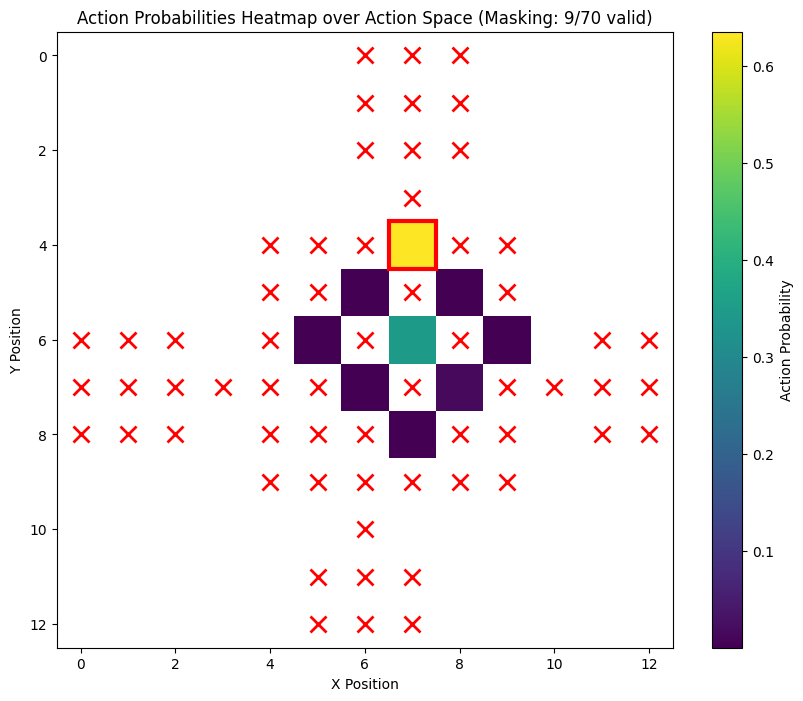

Episode 1 | Total Reward: 9.05 | Steps: 13
Episode 2 | Total Reward: 4.04 | Steps: 13
Episode 3 | Total Reward: 3.04 | Steps: 9
Episode 4 | Total Reward: 4.04 | Steps: 9
Episode 5 | Total Reward: 2.04 | Steps: 18
Episode 6 | Total Reward: 1.15 | Steps: 12
Episode 7 | Total Reward: 2.07 | Steps: 10
Episode 8 | Total Reward: 5.04 | Steps: 9
Episode 9 | Total Reward: 2.00 | Steps: 7
Episode 10 | Total Reward: 1.15 | Steps: 8


In [13]:
# Load trained agent and visualize
loaded_ppo_agent = RecurrentPPOAgent.load_complete(
    'models/PPO_GTrXL_test.pkl',
    env_constructor=lambda: VoltageDistributionEnv(),
    feature_extractor_constructor=lambda obs_space: CustomFeatureExtractor(obs_space)
)

# Run visualization with action probability heatmap
visualize_ppo_agent(loaded_ppo_agent, episodes=10, render_delay=0.1, use_action_masking=True)